# 5 · Modelos estocásticos: la incertidumbre
**Torre del Caribe** · Universidad Nacional Rosario Castellanos · Licenciatura en Ciencia de Datos para Negocios, 5.º
semestre 2026-2 · Equipo 2

| | |
|---|---|
| **Materia (UCA)** | Modelos Estocásticos para la Toma de Decisiones |
| **Profesor** | René Chablé García |
| **Criterio de la rúbrica** | 5. Modelos estocásticos (10 %) |
| **Equipo** | Brandon Uriel García Sánchez · Maribel Mondragón Mercado · Jesús Ramírez Isidro · Enrique González Ortega |

La campaña decide con cosas que no se saben de antemano: si llega una tormenta, si el norte se va a llenar
la semana que entra, cuántos visitantes habrá en un mes malo. En este notebook modelamos esa incertidumbre con tres
herramientas: un **proceso de Poisson** para las tormentas, una **cadena de Markov** para la ocupación semanal del norte
y una **simulación Monte Carlo** de 10,000 futuros para los visitantes del sur.

| Parte | Qué respondemos |
|---|---|
| 1. Las tormentas | ¿Qué cuenta como una tormenta que afecta al sur? |
| 2. Poisson | ¿Qué probabilidad hay de una tormenta en cada mes? ¿Se vale usar Poisson? |
| 3. Cadena de Markov | Si el norte está tranquilo hoy, ¿qué tan probable es que se sature en unas semanas? |
| 4. Monte Carlo | ¿Cuántos visitantes habrá en un año malo, normal o bueno? |
| 5. Sensibilidad | ¿Qué mueve más a los visitantes: la lluvia o el tipo de cambio? |
| 6. Resumen de hiperparámetros | Cada valor que elegimos, por qué y qué descartamos |

**Cómo leer este notebook.** Antes de cada celda de código explicamos qué hacemos y por qué; dentro del código, cada
renglón lleva su comentario. Al terminar cada paso comparamos nuestro resultado con el que guardó el proyecto (función
`coincide`): si una cifra no coincidiera, el notebook se detendría ahí. El documento técnico del equipo
(*Torre_del_Caribe.pdf*) tiene las fórmulas con su ejemplo resuelto a mano.

**Cómo correrlo.** Python 3.11 con `pip install -r requirements.txt` desde la carpeta de la entrega; abrir en Jupyter o
VS Code y elegir *Ejecutar todo*. Ya viene ejecutado, así que también se puede leer sin correrlo.

In [1]:
%matplotlib inline
# Preparación. Buscamos la carpeta de la entrega (la que tiene datos/silver), cargamos las librerías,
# definimos el estilo de las gráficas y la función que compara nuestras cifras con las del proyecto.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

warnings.filterwarnings("ignore")                        # avisos de versiones de librerías que no cambian resultados
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "silver").is_dir())
SILVER, GOLD = RAIZ / "datos" / "silver", RAIZ / "datos" / "gold"   # datos limpios y resultados del proyecto
FIGURAS = Path.cwd() / "figuras"                          # aquí guardamos cada gráfica como PNG
FIGURAS.mkdir(exist_ok=True)

# Colores institucionales de la UNRC (guinda y dorado) y una paleta para varias series.
GUINDA, DORADO, GRIS = "#9F2241", "#BC955C", "#3A3A3A"
PALETA = ["#9F2241", "#BC955C", "#565393", "#58A65D", "#8CAFDD", "#F26E50", "#465973"]
for f in (RAIZ / "herramientas" / "fuentes").glob("NotoSans-*.ttf"):
    font_manager.fontManager.addfont(str(f))          # la letra Noto Sans viene en la entrega
plt.rcParams.update({"font.family": "Noto Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlecolor": GUINDA, "axes.titlesize": 12,
                     "text.color": GRIS, "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
                     "figure.facecolor": "white", "savefig.dpi": 160, "savefig.bbox": "tight"})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)


def coincide(nombre, nuestro, proyecto, tolerancia=1e-6):
    """Compara un resultado de este notebook con el que guardó el proyecto. Si no coincide, se detiene."""
    a = np.asarray(nuestro, dtype=float).ravel()
    b = np.asarray(proyecto, dtype=float).ravel()
    assert a.shape == b.shape, f"{nombre}: tamaños distintos {a.shape} y {b.shape}"
    dif = float(np.nanmax(np.abs(a - b))) if len(a) else 0.0
    print(f"{'✓' if dif <= tolerancia else '✗'} {nombre}: coincide con el proyecto (diferencia máxima {dif:.2g})")
    assert dif <= tolerancia, f"{nombre} no coincide con el proyecto"


def guardar(fig, nombre):
    """Guarda la gráfica en figuras/ con un nombre claro."""
    fig.savefig(FIGURAS / f"{nombre}.png")


print("Carpeta de la entrega:", RAIZ)

Carpeta de la entrega: C:\Users\Uriel\Desktop\PP 5to semestre CASCO SANTO TOMAS\Entregable


## 1. Las tormentas que afectan al sur
Usamos **HURDAT2**, la base oficial de huracanes del Atlántico de la NOAA (Centro Nacional de Huracanes de Estados
Unidos). Trae la posición de cada tormenta cada 6 horas desde 1851, con su viento máximo. En el notebook de grandes
volúmenes de datos se ve cómo la descargamos y limpiamos; aquí la leemos ya limpia.

In [2]:
# Leemos las posiciones de todas las tormentas del Atlántico, una fila cada 6 horas.
columnas = ["id_tormenta", "nombre", "anio", "mes", "fecha", "hora_utc", "lat", "lon", "viento_kt", "km_chetumal"]
h = pd.read_parquet(SILVER / "huracanes", columns=columnas)
h["anio"] = h.anio.astype(int)          # el año viene como categoría (la tabla está partida por año); lo pasamos a número
h["mes"] = h.mes.astype(int)
print(f"{len(h):,} posiciones de {h.id_tormenta.nunique():,} tormentas, de {h.anio.min()} a {h.anio.max()}")
h.head()

55,524 posiciones de 1,988 tormentas, de 1851 a 2025


,id_tormenta,nombre,anio,mes,fecha,hora_utc,lat,lon,viento_kt,km_chetumal
0,AL011851,UNNAMED,1851,6,1851-06-25,0,28.0,-94.8,80.0,1247.1
1,AL011851,UNNAMED,1851,6,1851-06-25,600,28.0,-95.4,80.0,1280.6
2,AL011851,UNNAMED,1851,6,1851-06-25,1200,28.0,-96.0,80.0,1316.2
3,AL011851,UNNAMED,1851,6,1851-06-25,1800,28.1,-96.5,80.0,1355.7
4,AL011851,UNNAMED,1851,6,1851-06-25,2100,28.2,-96.8,80.0,1383.2


Para saber qué tan cerca pasó cada punto calculamos la **distancia sobre la Tierra** con la fórmula del
haversine (la Tierra como esfera de radio 6,371 km):

$$d = 2R\,\arcsin\sqrt{\sin^2\tfrac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\,\sin^2\tfrac{\Delta\lambda}{2}}$$

donde $\varphi$ es la latitud y $\lambda$ la longitud, en radianes. El punto de referencia es la bahía de Chetumal
(18.50° N, 88.30° O).

In [3]:
CHETUMAL = (18.50, -88.30)              # centro del sur de Quintana Roo (bahía de Chetumal)

def km_haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos de la Tierra (fórmula del haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))   # grados → radianes
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))                              # 6,371 km = radio medio de la Tierra

h["km"] = km_haversine(h.lat, h.lon, *CHETUMAL).round(1)                  # distancia de cada punto a Chetumal
con_lat = h.lat.notna()                                                  # dos líneas del archivo oficial vienen sin latitud
coincide("distancia a Chetumal", h.km[con_lat], h.km_chetumal[con_lat].astype(float), tolerancia=0.051)

✓ distancia a Chetumal: coincide con el proyecto (diferencia máxima 0)


Ahora definimos qué es **una tormenta que afecta al sur**. Hay tres decisiones, y cada una tiene su
razón:

| Hiperparámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|
| Radio alrededor de Chetumal | **200 km** | A esa distancia los vientos de tormenta tropical y la lluvia fuerte llegan a la costa del sur. Es el radio que deja suficientes eventos para estimar una tasa por mes | **100 km**: solo quedan 13 eventos en 60 años, muy pocos para 12 meses. **300 km**: 59 eventos, pero ya entran tormentas que pasan por el norte de Yucatán y por Honduras, que no afectan al sur |
| Viento mínimo | **34 nudos** (63 km/h) | Es el umbral oficial a partir del cual un sistema es **tormenta tropical** (o huracán). Debajo es una depresión, que casi no cambia los planes de un viajero | Contar también depresiones (más eventos, pero con poco efecto) |
| Desde qué año | **1966** | Desde ese año hay vigilancia por satélite continua; antes, las tormentas en el mar se perdían | **Desde 1851**: 0.469 tormentas por año contra 0.517 desde 1966; la diferencia es por tormentas que no se vieron, no por clima |

Abajo calculamos cuántos eventos quedan con cada radio, para ver la diferencia con los datos.

In [4]:
RADIO_KM, VIENTO_MIN_KT, DESDE = 200, 34, 1966     # la definición del equipo

def eventos(radio, viento=VIENTO_MIN_KT, desde=DESDE):
    """Una fila por tormenta que cumple la definición: su primer punto dentro del radio con ese viento, desde ese año."""
    cumple = (h.km <= radio) & (h.viento_kt >= viento) & (h.anio >= desde)
    x = h[cumple].sort_values(["fecha", "hora_utc"])              # en orden de tiempo, para tomar el primer punto
    return (x.groupby("id_tormenta")
              .agg(nombre=("nombre", "first"), anio=("anio", "first"), mes=("mes", "first"),
                   viento_max_kt=("viento_kt", "max"), km_min=("km", "min"))
              .reset_index().sort_values(["anio", "mes"]).reset_index(drop=True))

for r in (100, 200, 300):                                       # el efecto de elegir el radio
    print(f"Radio {r} km: {len(eventos(r))} eventos desde {DESDE}")
print(f"Desde 1851 con 200 km: {len(eventos(200, desde=1851)) / (2025 - 1851 + 1):.3f} por año "
      f"(desde 1966: {len(eventos(200)) / 60:.3f})")
ev = eventos(RADIO_KM)
ev.tail(8)

Radio 100 km: 13 eventos desde 1966
Radio 200 km: 31 eventos desde 1966
Radio 300 km: 59 eventos desde 1966
Desde 1851 con 200 km: 0.469 por año (desde 1966: 0.517)


,id_tormenta,nombre,anio,mes,viento_max_kt,km_min
23,AL072017,FRANKLIN,2017,8,50.0,88.5
24,AL032020,CRISTOBAL,2020,6,35.0,190.1
25,AL162020,NANA,2020,9,65.0,189.0
26,AL252020,GAMMA,2020,10,55.0,183.6
27,AL072021,GRACE,2021,8,75.0,190.2
28,AL152022,LISA,2022,11,80.0,115.6
29,AL152024,NADINE,2024,10,50.0,111.7
30,AL192024,SARA,2024,11,35.0,166.8


## 2. Poisson: la probabilidad de tormenta en cada mes
### Por qué Poisson
Lo que queremos saber es **cuántas tormentas** afectan al sur en un mes. Un proceso de Poisson describe justo eso:
eventos que

1. son **raros** (en 60 años hubo 31, unos 0.5 por año);
2. son **independientes** entre sí (que pase una no hace más o menos probable la siguiente, en la escala de un mes);
3. se cuentan **en un intervalo fijo** (un mes) con una **tasa promedio** $\lambda$.

La tasa **no es la misma todo el año**: casi todas las tormentas llegan de junio a noviembre. Por eso no usamos un solo
$\lambda$, sino **uno por mes del calendario** ($\lambda_m$). Es un proceso de Poisson **no homogéneo** en el año
(la tasa cambia con la temporada) que suponemos **estable de un año a otro** para cada mes. Esa segunda suposición la
probamos más abajo.

Con 60 años de datos, la mejor estimación de $\lambda_m$ es el promedio de eventos por año en ese mes:

$$\hat\lambda_m = \frac{\text{eventos que empezaron en el mes } m}{60\ \text{años}}, \qquad
P(\text{al menos una tormenta en el mes } m) = 1 - P(N=0) = 1 - e^{-\hat\lambda_m}$$

**Ejemplo a mano (agosto).** Hubo 9 eventos en 60 años: $\hat\lambda = 9/60 = 0.15$. La probabilidad de al menos una
tormenta es $1 - e^{-0.15} = 1 - 0.8607 = 0.139$, es decir, **14 %**.

In [5]:
ANIOS = 2025 - DESDE + 1                                       # 60 años: 1966 a 2025
p = pd.DataFrame({"mes": range(1, 13)})
p["eventos"] = p.mes.map(ev.mes.value_counts()).fillna(0).astype(int)   # cuántos eventos empezaron en cada mes
p["lambda"] = p.eventos / ANIOS                                     # tasa promedio por año en ese mes
p["prob_tormenta"] = 1 - np.exp(-p["lambda"])                       # P(al menos una) = 1 − e^(−λ)
print(f"Agosto: λ = {p.loc[7, 'lambda']:.3f}, P = 1 − e^(−λ) = {p.loc[7, 'prob_tormenta']:.3f}")
proyecto = pd.read_parquet(GOLD / "pronostico_poisson_tormentas.parquet")
coincide("λ por mes", p["lambda"], proyecto["lambda"])
coincide("probabilidad de tormenta por mes", p.prob_tormenta, proyecto.prob_tormenta)
p.round(4)

Agosto: λ = 0.150, P = 1 − e^(−λ) = 0.139
✓ λ por mes: coincide con el proyecto (diferencia máxima 0)
✓ probabilidad de tormenta por mes: coincide con el proyecto (diferencia máxima 0)


,mes,eventos,lambda,prob_tormenta
0,1,0,0.0000,0.0000
1,2,0,0.0000,0.0000
2,3,0,0.0000,0.0000
3,4,0,0.0000,0.0000
4,5,1,0.0167,0.0165
5,6,3,0.0500,0.0488
6,7,1,0.0167,0.0165
7,8,9,0.1500,0.1393
8,9,8,0.1333,0.1248
9,10,6,0.1000,0.0952


### Prueba 1: ¿los conteos se comportan como Poisson?
En una distribución de Poisson **la varianza es igual a la media**. Si los conteos por año tuvieran mucha más varianza
(años con muchas tormentas juntas y años vacíos), Poisson se quedaría corto y convendría una **binomial negativa**.
Lo probamos con el **índice de dispersión**: con $n$ años, el estadístico $D = (n-1)\,s^2/\bar x$ sigue una
$\chi^2$ con $n-1$ grados de libertad si los datos son Poisson.

In [6]:
from scipy import stats

por_anio = ev.groupby("anio").size().reindex(range(DESDE, 2026), fill_value=0)   # tormentas en cada año (0 si ninguna)
media, varianza = por_anio.mean(), por_anio.var(ddof=1)
D = (len(por_anio) - 1) * varianza / media                         # estadístico de dispersión
p_disp = stats.chi2.sf(D, len(por_anio) - 1)                       # probabilidad de ver algo así si fuera Poisson
print(f"Media {media:.3f} · varianza {varianza:.3f} · índice de dispersión {varianza / media:.2f} (Poisson = 1)")
print(f"D = {D:.1f} con {len(por_anio) - 1} grados de libertad → p = {p_disp:.2f}")

# Cuántos años tuvieron 0, 1, 2 y 3 tormentas, contra lo que esperaría Poisson con la misma media
ajuste = pd.DataFrame({"años observados": por_anio.value_counts().reindex(range(4), fill_value=0)})
ajuste["años esperados (Poisson)"] = [round(len(por_anio) * stats.poisson.pmf(k, media), 1) for k in range(4)]
ajuste.index.name = "tormentas en el año"
ajuste

Media 0.517 · varianza 0.559 · índice de dispersión 1.08 (Poisson = 1)
D = 63.8 con 59 grados de libertad → p = 0.31


,años observados,años esperados (Poisson)
tormentas en el año,,
0,36,35.8
1,19,18.5
2,3,4.8
3,2,0.8


El índice de dispersión es 1.08 y $p = 0.31$: **no hay evidencia de que la varianza supere a la media**, y
los años observados con 0, 1, 2 y 3 tormentas se parecen a los que predice Poisson. Por eso no hizo falta una binomial
negativa.

### Prueba 2: ¿la tasa es estable en el tiempo?
Un profesor podría preguntar por el cambio climático. Comparamos las dos mitades del periodo: si la tasa fuera la misma,
cada evento tendría 50 % de probabilidad de caer en la segunda mitad (prueba binomial).

In [7]:
a = int((ev.anio <= 1995).sum())                                  # eventos en 1966–1995
b = int((ev.anio >= 1996).sum())                                   # eventos en 1996–2025
p_tend = stats.binomtest(b, a + b, 0.5).pvalue                     # ¿es raro ver b de a+b en la segunda mitad?
print(f"1966–1995: {a} eventos · 1996–2025: {b} eventos · prueba binomial p = {p_tend:.3f}")

# Qué pasaría si usáramos solo los últimos 30 años (sensibilidad)
recientes = ev[ev.anio >= 1996]
p30 = recientes.mes.value_counts().reindex(range(1, 13), fill_value=0) / 30
comparar = pd.DataFrame({"P con 60 años": p.set_index("mes").prob_tormenta, "P con 30 años": 1 - np.exp(-p30)})
comparar.loc[6:11].round(3)

1966–1995: 10 eventos · 1996–2025: 21 eventos · prueba binomial p = 0.071


,P con 60 años,P con 30 años
mes,,
6,0.049,0.064
7,0.017,0.000
8,0.139,0.234
9,0.125,0.095
10,0.095,0.154
11,0.049,0.064


En la segunda mitad hubo el doble de eventos (21 contra 10), pero con tan pocos casos la diferencia **no
es significativa al 5 %** ($p = 0.071$). Por eso nos quedamos con los 60 años: usan toda la información que hay y la
diferencia podría ser azar. Lo declaramos como **limitación**: si la tendencia sigue, la probabilidad real en agosto y
septiembre sería más alta (la tabla de arriba muestra cuánto con 30 años). La campaña no depende solo de esta cifra: la
Torre en vivo pausa los anuncios cuando hay una tormenta real cerca, sin esperar a la probabilidad.

### Prueba 3: ¿qué tan precisa es cada probabilidad?
Con pocos eventos por mes, cada $\hat\lambda_m$ tiene incertidumbre. Calculamos su **intervalo exacto al 90 %**
(método de Garwood, con la distribución $\chi^2$). Para los meses **sin ningún evento** el modelo da 0 %, pero eso es
demasiado seguro: no haber visto tormentas en 60 años no prueba que nunca haya. El límite superior de esos meses es
$\lambda \le 3/60$ (la "regla del 3"), o sea, hasta un **4.9 %**.

,mes,eventos,lambda,prob_tormenta,P_inferior_90,P_superior_90
0,1,0,0.000,0.000,0.000,0.049
1,2,0,0.000,0.000,0.000,0.049
2,3,0,0.000,0.000,0.000,0.049
3,4,0,0.000,0.000,0.000,0.049
4,5,1,0.017,0.017,0.001,0.076
5,6,3,0.050,0.049,0.014,0.121
6,7,1,0.017,0.017,0.001,0.076
7,8,9,0.150,0.139,0.075,0.230
8,9,8,0.133,0.125,0.064,0.214
9,10,6,0.100,0.095,0.043,0.179


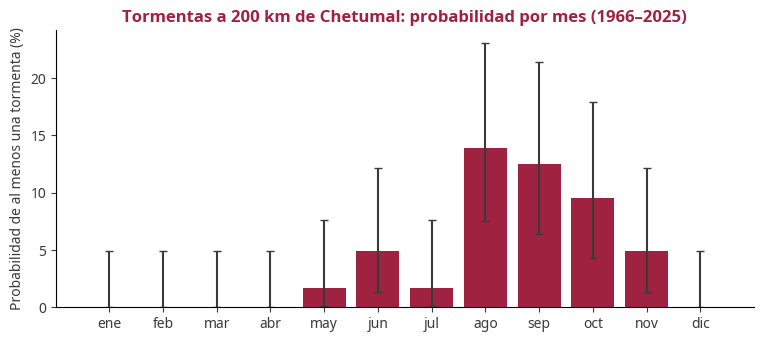

In [8]:
k = p.eventos.to_numpy()
inf = np.where(k > 0, stats.chi2.ppf(0.05, 2 * k) / 2, 0) / ANIOS       # límite inferior de λ (Garwood, 90 %)
sup = stats.chi2.ppf(0.95, 2 * k + 2) / 2 / ANIOS                       # límite superior de λ
p["P_inferior_90"] = 1 - np.exp(-inf)
p["P_superior_90"] = 1 - np.exp(-sup)
NOMBRES_MES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(NOMBRES_MES, p.prob_tormenta * 100, color=GUINDA)                            # la probabilidad estimada
ax.errorbar(NOMBRES_MES, p.prob_tormenta * 100, yerr=[(p.prob_tormenta - p.P_inferior_90) * 100,
            (p.P_superior_90 - p.prob_tormenta) * 100], fmt="none", ecolor=GRIS, capsize=3)   # su intervalo al 90 %
ax.set_ylabel("Probabilidad de al menos una tormenta (%)")
ax.set_title("Tormentas a 200 km de Chetumal: probabilidad por mes (1966–2025)")
guardar(fig, "5_poisson_por_mes")
p[["mes", "eventos", "lambda", "prob_tormenta", "P_inferior_90", "P_superior_90"]].round(3)

### Alternativas que consideramos para las tormentas

| Alternativa | Por qué no la usamos |
|---|---|
| **Frecuencia simple** (años con tormenta ÷ 60) | Da casi lo mismo con tasas tan bajas, pero no permite simular más de una tormenta en un mes ni calcular intervalos con una distribución conocida |
| **Binomial negativa** | Sirve cuando la varianza supera mucho a la media. La prueba 1 no lo muestra ($p = 0.31$), así que agregaría un parámetro sin necesidad |
| **Poisson con tendencia** (regresión de Poisson con el año) | La tendencia no es significativa al 5 % (prueba 2) y con 31 eventos la pendiente sería muy inestable |
| **Solo los últimos 30 años** | Más actual, pero con la mitad de los datos; queda como sensibilidad |
| **Un solo λ para todo el año** | Ignora la temporada: daría 4 % todos los meses, también en abril |

### El Excel de Poisson
Guardamos el mismo cálculo en un Excel con **fórmulas vivas** (`CONTAR.SI`, `EXP`, `POISSON.DIST`, `INV.CHICUAD`) para
revisarlo celda por celda. Junto a cada fórmula va el valor que calculamos aquí en Python, para comprobar que coinciden.

In [9]:
from openpyxl import Workbook
from openpyxl.chart import BarChart, Reference
from openpyxl.styles import Alignment, Font, PatternFill

wb = Workbook()                                                    # las funciones nuevas de Excel llevan el prefijo _xlfn. en el archivo
titulo, guinda = Font(bold=True, color="FFFFFF"), PatternFill("solid", fgColor="9F2241")

def encabezado(ws, columnas):
    """Primera fila de una hoja: nombres de columna en blanco sobre guinda."""
    ws.append(columnas)
    for c in ws[1]:
        c.font, c.fill, c.alignment = titulo, guinda, Alignment(wrap_text=True, vertical="center")

# Hoja 1: qué es cada cosa
ws = wb.active; ws.title = "Léeme"
for renglon in ["Torre del Caribe · Probabilidad de tormenta por mes (proceso de Poisson)",
                "Fuente: HURDAT2 (NOAA). Evento = tormenta tropical o huracán (≥ 34 nudos) a ≤ 200 km de Chetumal, 1966–2025.",
                "λ_m = eventos que empezaron en el mes m ÷ 60 años.  P(al menos una tormenta) = 1 − EXP(−λ_m).",
                "Las columnas en gris son el mismo valor calculado en Python (notebook 5) para comprobar las fórmulas.",
                "Hojas: Eventos (los 31 casos), Poisson por mes, Prueba de dispersión, Tendencia."]:
    ws.append([renglon])
ws["A1"].font = Font(bold=True, size=13, color="9F2241"); ws.column_dimensions["A"].width = 110

# Hoja 2: los 31 eventos (los datos de entrada)
ws = wb.create_sheet("Eventos")
encabezado(ws, ["Tormenta", "Nombre", "Año", "Mes", "Viento máximo (nudos)", "Distancia mínima a Chetumal (km)"])
for f in ev.itertuples():
    ws.append([f.id_tormenta, f.nombre, int(f.anio), int(f.mes), float(f.viento_max_kt), float(f.km_min)])

# Hoja 3: Poisson por mes, con fórmulas
ws = wb.create_sheet("Poisson por mes")
encabezado(ws, ["Mes", "Nombre", "Eventos", "Años", "λ (por año)", "P(al menos una)", "P(0)", "P(1)", "P(2 o más)",
                "λ inferior 90 %", "λ superior 90 %", "P inferior 90 %", "P superior 90 %", "P en Python"])
for i, f in enumerate(p.itertuples(), start=2):
    ws.append([f.mes, NOMBRES_MES[f.mes - 1],
               f"=COUNTIF(Eventos!D:D,A{i})", 60, f"=C{i}/D{i}", f"=1-EXP(-E{i})",
               f"=_xlfn.POISSON.DIST(0,E{i},FALSE)", f"=_xlfn.POISSON.DIST(1,E{i},FALSE)", f"=1-G{i}-H{i}",
               f"=IF(C{i}=0,0,_xlfn.CHISQ.INV(0.05,2*C{i})/2/D{i})", f"=_xlfn.CHISQ.INV(0.95,2*C{i}+2)/2/D{i}",
               f"=1-EXP(-J{i})", f"=1-EXP(-K{i})", round(float(f.prob_tormenta), 6)])
    ws[f"N{i}"].fill = PatternFill("solid", fgColor="E6E6E6")
grafica = BarChart(); grafica.title = "Probabilidad de al menos una tormenta"; grafica.y_axis.title = "P"
grafica.add_data(Reference(ws, min_col=6, min_row=1, max_row=13), titles_from_data=True)
grafica.set_categories(Reference(ws, min_col=2, min_row=2, max_row=13))
ws.add_chart(grafica, "P2")

# Hoja 4: prueba de dispersión con los conteos por año
ws = wb.create_sheet("Prueba de dispersión")
encabezado(ws, ["Año", "Tormentas", "", "Cálculo", "Fórmula", "Python"])
for i, anio in enumerate(por_anio.index, start=2):
    ws.append([int(anio), f"=COUNTIF(Eventos!C:C,A{i})"])
n_fin = len(por_anio) + 1
calculos = [("Media", f"=AVERAGE(B2:B{n_fin})", media), ("Varianza", f"=_xlfn.VAR.S(B2:B{n_fin})", varianza),
            ("Índice de dispersión (varianza ÷ media)", "=E3/E2", varianza / media),
            ("Estadístico D = (n−1)·varianza ÷ media", f"=(COUNT(B2:B{n_fin})-1)*E3/E2", D),
            ("p-valor (χ² con n−1 grados)", f"=_xlfn.CHISQ.DIST.RT(E5,COUNT(B2:B{n_fin})-1)", p_disp)]
for j, (nombre, formula, valor) in enumerate(calculos, start=2):
    ws[f"D{j}"], ws[f"E{j}"], ws[f"F{j}"] = nombre, formula, round(float(valor), 6)
for j, kk in enumerate(range(4), start=9):
    ws[f"D{j}"] = f"Años con {kk} tormentas: observados / esperados"
    ws[f"E{j}"] = f"=COUNTIF(B2:B{n_fin},{kk})"
    ws[f"F{j}"] = f"=COUNT(B2:B{n_fin})*_xlfn.POISSON.DIST({kk},E2,FALSE)"

# Hoja 5: tendencia (dos mitades) y sensibilidad con 30 años
ws = wb.create_sheet("Tendencia")
encabezado(ws, ["Cálculo", "Fórmula", "Python"])
ws.append(["Eventos 1966–1995", '=COUNTIF(Eventos!C:C,"<=1995")', a])
ws.append(["Eventos 1996–2025", '=COUNTIF(Eventos!C:C,">=1996")', b])
ws.append(["Total", "=B2+B3", a + b])
ws.append(["p-valor binomial de dos colas (misma tasa = 50 % en cada mitad)", "=MIN(1,2*(1-_xlfn.BINOM.DIST(B3-1,B4,0.5,TRUE)))",
           round(float(p_tend), 6)])
ws.append([])
ws.append(["Mes", "P con 60 años", "P con 30 años (1996–2025)"])
for m in range(1, 13):
    fila = ws.max_row + 1
    ws.append([m, f"=1-EXP(-COUNTIF(Eventos!D:D,A{fila})/60)",
               f'=1-EXP(-COUNTIFS(Eventos!D:D,A{fila},Eventos!C:C,">=1996")/30)'])
for hoja in wb.worksheets[1:]:
    for col in "ABCDEFGHIJKLMN":
        hoja.column_dimensions[col].width = 16
wb["Prueba de dispersión"].column_dimensions["D"].width = 46
wb["Tendencia"].column_dimensions["A"].width = 60
EXCEL = Path.cwd() / "5_Poisson_tormentas.xlsx"
wb.save(EXCEL)
print("Excel guardado:", EXCEL.name, "·", ", ".join(wb.sheetnames))

Excel guardado: 5_Poisson_tormentas.xlsx · Léeme, Eventos, Poisson por mes, Prueba de dispersión, Tendencia


## 3. Cadena de Markov semanal del norte
### La pregunta
Si Cancún está "concurrido" esta semana, ¿qué tan probable es que esté "saturado" en 4 semanas? Esa es la señal para
ofrecerle el sur al turista que iba al norte. DataTur publica la **ocupación hotelera semanal** de 7 centros turísticos
del norte (cuartos ocupados ÷ cuartos disponibles). El sur no tiene datos semanales, así que la cadena describe solo al
norte, como referencia.

### Los estados
Cada semana de cada centro la clasificamos en tres estados con los **percentiles 50 y 90** de toda la ocupación semanal
de los 7 centros juntos: debajo de la mediana es *tranquilo*; entre la mediana y el percentil 90, *concurrido*; arriba,
*saturado*.

In [10]:
o = pd.read_parquet(SILVER / "datatur_ocupacion",
                    columns=["centro", "es_qroo", "frecuencia", "periodo", "cuartos_ocupados", "cuartos_disponibles"])
o = o[o.es_qroo & (o.frecuencia == "semanal")].copy()                  # solo la serie semanal de Quintana Roo
o["semana"] = pd.to_datetime(o.periodo.astype(str))
o["ocupacion_pct"] = 100 * o.cuartos_ocupados / o.cuartos_disponibles  # ocupación de la semana
o = o[["centro", "semana", "ocupacion_pct"]].sort_values(["centro", "semana"], ignore_index=True)

ESTADOS = ["tranquilo", "concurrido", "saturado"]
u50, u90 = np.quantile(o.ocupacion_pct, (0.50, 0.90))                  # cortes comunes a los 7 centros
o["estado"] = np.select([o.ocupacion_pct < u50, o.ocupacion_pct <= u90], ESTADOS[:2], default=ESTADOS[2])
print(f"{o.centro.nunique()} centros · {len(o):,} semanas-centro · cortes: p50 = {u50:.1f} %, p90 = {u90:.1f} %")
o.estado.value_counts()

7 centros · 1,673 semanas-centro · cortes: p50 = 71.2 %, p90 = 85.9 %


estado
tranquilo     836
concurrido    669
saturado      168
Name: count, dtype: int64

### Las transiciones y la matriz
Contamos cuántas veces un centro pasó de cada estado a cada estado de una semana a la siguiente, $n_{ij}$, solo
cuando las dos semanas son consecutivas. La **estimación de máxima verosimilitud** de una cadena de Markov es contar y
dividir:

$$\hat p_{ij} = \frac{n_{ij}}{\sum_j n_{ij}}$$

La **propiedad de Markov** dice que la semana que viene depende solo de esta semana, no de las anteriores. Con la
ocupación hotelera es razonable a corto plazo: un hotel lleno esta semana suele seguir lleno la próxima.

In [11]:
sig = o.groupby("centro").shift(-1)                                    # la semana siguiente del mismo centro
consecutiva = (sig.semana - o.semana) == pd.Timedelta(days=7)          # solo si de verdad es la semana siguiente
tr = pd.DataFrame({"centro": o.centro, "semana": o.semana, "desde": o.estado, "hacia": sig.estado})[consecutiva]

n = pd.crosstab(tr.desde, tr.hacia).reindex(index=ESTADOS, columns=ESTADOS, fill_value=0)   # conteos n_ij
P = n.div(n.sum(axis=1), axis=0)                                       # p_ij = n_ij / Σ_j n_ij
coincide("matriz de transición", P, pd.read_parquet(GOLD / "radar_markov_matriz.parquet").reindex(index=ESTADOS, columns=ESTADOS))
print(f"Transiciones contadas: {int(n.to_numpy().sum()):,}")
P.round(3)

✓ matriz de transición: coincide con el proyecto (diferencia máxima 0)
Transiciones contadas: 1,666


hacia,tranquilo,concurrido,saturado
desde,,,
tranquilo,0.922,0.078,0.000
concurrido,0.100,0.831,0.069
saturado,0.012,0.262,0.726


**Cómo se lee.** Si esta semana está *saturado*, la siguiente sigue saturado con probabilidad 0.73 y pasa a
concurrido con 0.26. Para varias semanas multiplicamos la matriz: la distribución dentro de $k$ semanas es
$\pi_{t+k} = \pi_t P^k$. La **distribución estacionaria** $\pi = \pi P$ dice qué fracción de semanas pasa el norte
en cada estado a largo plazo.

A largo plazo: {'tranquilo': 0.513, 'concurrido': 0.389, 'saturado': 0.098}


P(saturado) en k semanas,1,2,3,4,5,6,7,8
estado de hoy,,,,,,,,
tranquilo,0.000,0.005,0.013,0.022,0.031,0.040,0.047,0.054
concurrido,0.069,0.107,0.127,0.136,0.139,0.138,0.135,0.132
saturado,0.726,0.545,0.424,0.342,0.284,0.243,0.213,0.191


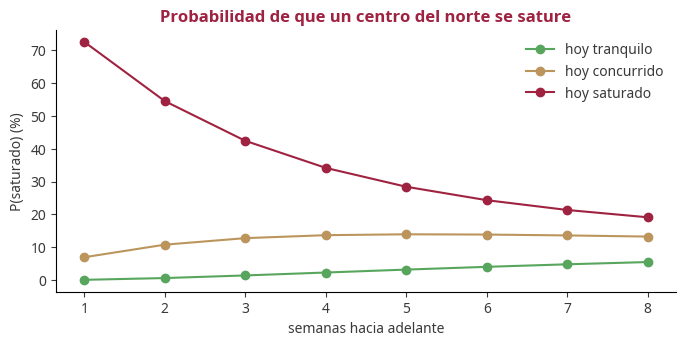

In [12]:
def a_k_semanas(estado, k):
    """Probabilidad de cada estado dentro de k semanas, empezando en `estado` (π_t = 1 en ese estado)."""
    pi = np.array([e == estado for e in ESTADOS], dtype=float)
    return pi @ np.linalg.matrix_power(P.to_numpy(), k)

val, vec = np.linalg.eig(P.to_numpy().T)                                # π es el vector propio de valor propio 1
pi = np.real(vec[:, np.argmin(np.abs(val - 1))]); pi = pi / pi.sum()
print("A largo plazo:", dict(zip(ESTADOS, pi.round(3))))
riesgo = pd.DataFrame({k: [a_k_semanas(e, k)[2] for e in ESTADOS] for k in range(1, 9)}, index=ESTADOS)
riesgo.index.name = "estado de hoy"; riesgo.columns.name = "P(saturado) en k semanas"

fig, ax = plt.subplots(figsize=(8, 3.4))
for e, c in zip(ESTADOS, [PALETA[3], DORADO, GUINDA]):
    ax.plot(riesgo.columns, riesgo.loc[e] * 100, marker="o", color=c, label=f"hoy {e}")
ax.set_xlabel("semanas hacia adelante"); ax.set_ylabel("P(saturado) (%)"); ax.legend(frameon=False)
ax.set_title("Probabilidad de que un centro del norte se sature")
guardar(fig, "5_markov_riesgo")
riesgo.round(3)

### ¿Sirve? La prueba contra modelos más simples
Un modelo solo vale si le gana a algo más sencillo. Para cada una de las **últimas 52 semanas** estimamos la matriz
**solo con el pasado** y predecimos 1, 4 y 8 semanas adelante. Lo comparamos con:

- **Persistencia**: "dentro de k semanas estará igual que hoy";
- **Frecuencia simple**: la proporción de semanas de cada estado en el pasado.

Usamos el **puntaje de Brier**, $\frac{1}{N}\sum (p_j - y_j)^2$ sumado sobre los tres estados, que mide qué tan buenas
son las **probabilidades** (0 es perfecto). La exactitud solo mira si el estado más probable acertó.

In [13]:
def matriz(transiciones):
    m = pd.crosstab(transiciones.desde, transiciones.hacia).reindex(index=ESTADOS, columns=ESTADOS, fill_value=0)
    return m.div(m.sum(axis=1), axis=0)

corte = o.semana.max() - pd.Timedelta(weeks=52)                        # las últimas 52 semanas son la prueba
por_centro = {c: g.set_index("semana").estado for c, g in o.groupby("centro")}
filas = []
for k in (1, 4, 8):
    brier = {"Markov": [], "Persistencia": [], "Frecuencia simple": []}
    aciertos = dict.fromkeys(brier, 0); casos = 0
    for semana in sorted(o.loc[o.semana > corte, "semana"].unique()):
        pasado = tr[tr.semana + pd.Timedelta(days=7) <= semana - pd.Timedelta(weeks=k - 1)]   # solo lo que ya se sabía
        Pk = np.linalg.matrix_power(matriz(pasado).to_numpy(), k)
        frec = o[o.semana <= semana - pd.Timedelta(weeks=k)].estado.value_counts(normalize=True).reindex(ESTADOS, fill_value=0)
        for c, serie in por_centro.items():
            origen = semana - pd.Timedelta(weeks=k)
            if origen not in serie.index or semana not in serie.index:
                continue
            real = np.array([serie[semana] == e for e in ESTADOS], dtype=float)
            hoy = np.array([serie[origen] == e for e in ESTADOS], dtype=float)
            pred = {"Markov": hoy @ Pk, "Persistencia": hoy, "Frecuencia simple": frec.to_numpy()}
            for nombre, q in pred.items():
                brier[nombre].append(((q - real) ** 2).sum())
                aciertos[nombre] += int(ESTADOS[int(np.argmax(q))] == serie[semana])
            casos += 1
    for nombre in brier:
        filas.append({"k_semanas": k, "metodo": nombre, "brier": round(float(np.mean(brier[nombre])), 3),
                      "exactitud": round(aciertos[nombre] / casos, 3), "casos": casos})
bt = pd.DataFrame(filas)
coincide("prueba de las últimas 52 semanas", bt[["brier", "exactitud"]], pd.read_parquet(GOLD / "radar_markov_backtest.parquet")[["brier", "exactitud"]])
bt.pivot(index="metodo", columns="k_semanas", values="brier")

✓ prueba de las últimas 52 semanas: coincide con el proyecto (diferencia máxima 0)


k_semanas,1,4,8
metodo,,,
Frecuencia simple,0.544,0.549,0.555
Markov,0.200,0.389,0.490
Persistencia,0.225,0.484,0.676


Markov tiene **el menor puntaje de Brier en los tres horizontes**: sus probabilidades son las más
confiables. En exactitud empata con la persistencia a 1 semana y queda un poco abajo a 4 y 8 semanas: la persistencia
acierta seguido porque los estados duran, pero sus "probabilidades" son 0 o 100 % y se equivoca con todo cuando cambia
el estado. Para decidir cuándo ofrecer el sur nos importa la probabilidad, así que Markov es el que usamos.

| Hiperparámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|
| Frecuencia | **Semanal** | El plan pide Markov en semanas y el pronóstico en meses, para que no se encimen | Mensual (repetía al clasificador del Radar) |
| Estados | **3** con cortes **p50 y p90** comunes | Los mismos cortes del Radar: "saturado" es el 10 % más lleno de todas las semanas | Terciles de cada centro (cada uno tendría su propio "lleno") |
| Una matriz para los 7 centros | Sí | Más de 1,600 transiciones; una matriz por centro tendría muy pocas desde *saturado* | Una por centro |
| Semanas de prueba | **52** | Un año completo, con todas las temporadas | Partición aleatoria (filtra el futuro) |
| Horizonte | **1 a 8 semanas** | Lo que tarda en planearse un viaje corto | Más de 8 (la cadena converge a la estacionaria y ya no informa) |

## 4. Monte Carlo: escenarios malo, probable y bueno
### La idea
El pronóstico (notebook 4) da un número esperado por mes, pero el futuro puede salir peor o mejor. Para saber **qué tan
peor**, simulamos 10,000 años posibles. Cada año simulado es:

$$\text{visitantes}_{r,m} = \text{pronóstico}_m \times e^{\,\varepsilon_{r,m}}$$

donde los errores $\varepsilon$ no los inventamos: son **errores reales** del pasado, $\varepsilon = \ln(\text{real} /
\text{pronóstico})$, que medimos al probar el modelo con origen móvil. Con los 10,000 años tomamos los percentiles
**10, 50 y 90**: escenario malo, probable y bueno.

### Por qué un año completo de errores a la vez
Si sorteáramos el error de cada mes por separado, un mes malo se compensaría con uno bueno y el rango del año saldría
demasiado angosto. En la realidad un año flojo suele ser flojo varios meses seguidos. Por eso cada futuro copia los 12
errores de **un mismo origen del pasado**, elegido al azar (un *bootstrap por bloques*). Si a ese origen le falta un
horizonte, ese mes se sortea entre los errores del mismo tramo de horizonte (1–3, 4–6 o 7–12 meses).

### La tormenta como supuesto
No pudimos medir cuántos visitantes se pierden en un mes con tormenta: solo hay 3 meses con tormenta en los datos usables
(Earl 2016, Franklin 2017 y Lisa 2022). Por eso no lo presentamos como dato: probamos tres supuestos (se pierde 0 %, 25 %
o 50 % del mes) y en cada futuro sorteamos si hay tormenta con el $\lambda_m$ de Poisson.

In [14]:
serie_t = pd.read_parquet(GOLD / "pronostico_series.parquet")          # las series mensuales (visitantes, cruces…)
pron = pd.read_parquet(GOLD / "pronostico_mes.parquet")                # el pronóstico de 12 meses del modelo elegido
bt_pron = pd.read_parquet(GOLD / "pronostico_backtest.parquet")         # los errores reales del origen móvil
R, SEMILLA = 10_000, 2026
GOLPES = (0.0, 0.25, 0.50)                                             # SUPUESTO: fracción que se pierde con tormenta
lam_mes = p.set_index("mes")["lambda"]

def tramo_h(h):
    return "1–3" if h <= 3 else "4–6" if h <= 6 else "7–12"

def simular(pr, golpe, rng, R=R):
    """Matriz R × 12 de futuros posibles para una serie (R futuros, 12 meses)."""
    b = bt_pron[(bt_pron.serie == pr.serie.iloc[0]) & (bt_pron.modelo == pr.modelo.iloc[0]) & (bt_pron.pronostico > 0)].copy()
    b["e"] = np.log(b.real / b.pronostico)                             # error en logaritmos: ln(real ÷ pronóstico)
    por_origen = {og: g.set_index("horizonte").e.reindex(range(1, 13)).to_numpy() for og, g in b.groupby("origen")}
    por_tramo = {kk: g.e.to_numpy() for kk, g in b.groupby("tramo_h")}
    origenes = list(por_origen)
    E = np.array([por_origen[origenes[i]] for i in rng.integers(len(origenes), size=R)])   # un año de errores por futuro
    for j, kk in enumerate(tramo_h(x) for x in pr.horizonte):
        vacios = np.isnan(E[:, j])                                      # horizontes que a ese origen le faltaron
        E[vacios, j] = rng.choice(por_tramo[kk], size=vacios.sum())
    D = pr.esperado_est.to_numpy()[None, :] * np.exp(E)               # pronóstico × e^error
    if golpe > 0 and pr.papel.iloc[0] == "promovida":
        lam = pr.periodo.dt.month.map(lam_mes).to_numpy()
        tormenta = rng.poisson(lam[None, :], size=D.shape) > 0          # ¿hubo tormenta ese mes en ese futuro?
        D = np.where(tormenta, D * (1 - golpe), D)
    return D

Ahora corremos los futuros de todas las series, en el mismo orden y con la misma semilla que el proyecto
(así los números al azar salen iguales y podemos comparar). Para cada mes guardamos los percentiles y el **riesgo de
rebasar la capacidad probada**: la fracción de futuros en los que el mes supera el mes más alto que el lugar ya recibió
en su historia. Esa capacidad no es la física oficial (no existe para las zonas arqueológicas), y así lo decimos.

In [15]:
AGREGADAS = {"Riviera Maya (referencia) · ocupación hotelera"}       # se agregó después: va al final, como en el proyecto
rng = np.random.default_rng(SEMILLA)
filas, anual = [], []
for serie in sorted(pron.serie.unique(), key=lambda x: (x in AGREGADAS, x)):
    pr = pron[pron.serie == serie].sort_values("periodo").reset_index(drop=True)
    hist = serie_t[(serie_t.serie == serie) & serie_t.entrena_flag]
    capacidad = float(hist.valor.max())                                 # el mes más alto que ya recibió
    for golpe in (GOLPES if pr.papel.iloc[0] == "promovida" else (0.0,)):
        D = simular(pr, golpe, rng)
        total = D.sum(axis=1)                                           # los visitantes del año en cada futuro
        anual.append({"serie": serie, "golpe": golpe, "malo_p10": np.percentile(total, 10),
                      "probable_p50": np.percentile(total, 50), "bueno_p90": np.percentile(total, 90),
                      "riesgo_algun_mes": float((D > capacidad).any(axis=1).mean())})
        q10, q50, q90 = np.percentile(D, [10, 50, 90], axis=0)          # malo, probable y bueno
        for j, f in pr.iterrows():
            filas.append({"serie": serie, "periodo": f.periodo, "golpe": golpe, "malo_p10": q10[j], "probable_p50": q50[j],
                          "bueno_p90": q90[j], "riesgo_capacidad": float((D[:, j] > capacidad).mean())})
mc = pd.DataFrame(filas)
esc = pd.read_parquet(GOLD / "pronostico_escenarios.parquet")
coincide("escenarios malo / probable / bueno", mc[["malo_p10", "probable_p50", "bueno_p90"]],
         esc[["malo_p10_est", "probable_p50_est", "bueno_p90_est"]], tolerancia=1e-6)
coincide("riesgo de rebasar la capacidad", mc.riesgo_capacidad, esc.riesgo_rebasar_capacidad)
anual = pd.DataFrame(anual)
esc_anual = pd.read_parquet(GOLD / "pronostico_escenarios_anual.parquet")
coincide("escenarios del año completo", anual[["malo_p10", "probable_p50", "bueno_p90"]],
         esc_anual[["malo_p10_est", "probable_p50_est", "bueno_p90_est"]])
anual.round({"malo_p10": 0, "probable_p50": 0, "bueno_p90": 0, "riesgo_algun_mes": 3})

✓ escenarios malo / probable / bueno: coincide con el proyecto (diferencia máxima 0)
✓ riesgo de rebasar la capacidad: coincide con el proyecto (diferencia máxima 0)
✓ escenarios del año completo: coincide con el proyecto (diferencia máxima 0)


,serie,golpe,malo_p10,probable_p50,bueno_p90,riesgo_algun_mes
0,Bahía Calderitas–Oxtankah · visitantes INAH,0.00,10106.0,11217.0,13085.0,0.242
1,Bahía Calderitas–Oxtankah · visitantes INAH,0.25,10030.0,11140.0,12947.0,0.243
2,Bahía Calderitas–Oxtankah · visitantes INAH,0.50,9915.0,11019.0,12777.0,0.243
3,Cancún (referencia) · ocupación hotelera,0.00,820.0,835.0,849.0,0.000
4,Chetumal · cruces desde Belice,0.00,551986.0,620304.0,671956.0,0.383
5,Chetumal · cruces desde Belice,0.25,546473.0,611505.0,661812.0,0.372
6,Chetumal · cruces desde Belice,0.50,535346.0,606138.0,660162.0,0.368
7,Ruta arqueológica del sur · visitantes INAH,0.00,55811.0,62212.0,73884.0,0.309
8,Ruta arqueológica del sur · visitantes INAH,0.25,55401.0,61923.0,73410.0,0.304
9,Ruta arqueológica del sur · visitantes INAH,0.50,54751.0,61440.0,72628.0,0.312


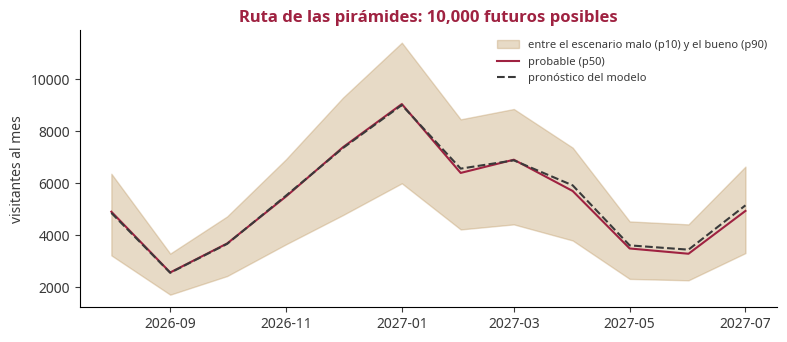

In [16]:
# Gráfica de abanico: la Ruta de las pirámides, sin golpe de tormenta
s = "Ruta arqueológica del sur · visitantes INAH"
x = mc[(mc.serie == s) & (mc.golpe == 0)]
pr = pron[pron.serie == s].sort_values("periodo")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(x.periodo, x.malo_p10, x.bueno_p90, color=DORADO, alpha=0.35, label="entre el escenario malo (p10) y el bueno (p90)")
ax.plot(x.periodo, x.probable_p50, color=GUINDA, label="probable (p50)")
ax.plot(pr.periodo, pr.esperado_est, color=GRIS, ls="--", label="pronóstico del modelo")
ax.set_ylabel("visitantes al mes"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Ruta de las pirámides: 10,000 futuros posibles")
guardar(fig, "5_monte_carlo_ruta")

### ¿Bastan 10,000 futuros?
El resultado de un Monte Carlo cambia un poco con la semilla. Si cambiamos la semilla y el escenario malo casi no se
mueve, el número de futuros es suficiente. Lo probamos con 1,000, 5,000, 10,000 y 20,000 futuros y diez semillas
distintas, con el total del año de la Ruta (el total es lo que usa el plan de presupuesto).

In [17]:
pr = pron[pron.serie == s].sort_values("periodo").reset_index(drop=True)
estabilidad = []
for r_prueba in (1_000, 5_000, 10_000, 20_000):
    p10 = [np.percentile(simular(pr, 0.0, np.random.default_rng(semilla), R=r_prueba).sum(axis=1), 10)
           for semilla in range(10)]                                   # el escenario malo del año con 10 semillas
    estabilidad.append({"futuros": r_prueba, "p10 del año (promedio)": np.mean(p10),
                        "variación entre semillas (% del p10)": np.std(p10) / np.mean(p10) * 100})
pd.DataFrame(estabilidad).round(2)

,futuros,p10 del año (promedio),variación entre semillas (% del p10)
0,1000,55810.00,0.16
1,5000,55810.59,0.00
2,10000,55810.59,0.00
3,20000,55810.59,0.00


Desde 5,000 futuros el escenario malo del año ya no cambia con la semilla. La razón es interesante: cada
futuro copia el año de errores de uno de los **48 orígenes** del pasado de la Ruta, así que solo hay unos 48 "años
posibles" distintos (más las variaciones de los meses que se rellenan sorteando). Con miles de futuros, el percentil 10
cae siempre en el mismo de esos años. **Lo que limita la precisión no es el número de futuros, sino cuántos años de
errores reales tenemos**, y eso lo declaramos: el escenario malo no puede ser peor que los peores errores que el modelo
ya cometió. Usamos 10,000 porque tarda segundos y deja estables también los meses sueltos.

| Hiperparámetro | Valor | Por qué | Qué descartamos |
|---|---|---|---|
| Número de futuros | **10,000** | Desde 5,000 el escenario malo del año ya no cambia con la semilla (tabla de arriba); tarda segundos | 1,000 (todavía se mueve un poco); 100,000 (no cambia nada, solo tarda más) |
| Escenarios | **Percentiles 10, 50 y 90** | Un año "malo" es uno que solo 1 de cada 10 futuros supera hacia abajo; es el mismo nivel del rango del pronóstico (90 %) | p5 y p95 (con estos pocos errores reales, las colas serían muy inestables) |
| Errores | **Reales, por bloques de un año** | Conservan que un año flojo es flojo varios meses | Errores normales inventados; sortear cada mes por separado (rango demasiado angosto) |
| Golpe de tormenta | **0 %, 25 %, 50 %** (supuesto) | No se pudo medir con 3 casos; se prueba un barrido y se dice | Fijar un solo número como si fuera dato |
| Capacidad | **El mes más alto ya recibido** | Es lo único medido que existe | La capacidad física oficial (no existe para las zonas arqueológicas) |
| Semilla | **2026** | Para que cualquiera obtenga los mismos números | Sin semilla (resultados distintos cada vez) |

## 5. Sensibilidad: ¿qué mueve más a los visitantes?
Medimos el efecto de dos variables con una regresión sobre el logaritmo de los visitantes:

$$\ln(\text{visitantes}_t) = \alpha_{\text{tramo}} + \gamma_{\text{mes}} + \beta\, x_t + e_t$$

donde $\alpha$ es un nivel por tramo (cada vez que la serie se interrumpe por cierre o pandemia empieza un tramo nuevo),
$\gamma$ es el efecto de cada mes del año y $x_t$ es la variable: la **lluvia del mes sobre lo normal** (en cientos de
mm, del reanálisis ERA5 de Open-Meteo, que tiene la serie mensual completa) o el **tipo de cambio** (pesos por dólar,
FRED). El efecto en porcentaje es $e^{\beta} - 1$.

In [18]:
import statsmodels.api as sm

PUNTO = {"Bahía Calderitas–Oxtankah": "chetumal", "Ruta arqueológica del sur": "kohunlich", "Chetumal": "chetumal"}
dia = pd.read_parquet(SILVER / "clima_diario", columns=["punto", "anio", "mes", "lluvia_mm"])
fx = pd.read_parquet(SILVER / "fred_mensual", columns=["periodo", "pesos_por_dolar"])
fx["periodo"] = pd.to_datetime(fx.periodo); fx = fx.set_index("periodo").pesos_por_dolar

def lluvia_mensual(punto):
    """Lluvia total de cada mes (suma de los días) en un punto, indexada por el primer día del mes."""
    d = dia[dia.punto == punto].assign(anio=lambda z: z.anio.astype(int))
    c = d.groupby(["anio", "mes"]).lluvia_mm.sum().reset_index()
    c["periodo"] = pd.to_datetime(dict(year=c.anio, month=c.mes, day=1))
    return c.set_index("periodo")

filas = []
for serie, sx in serie_t[serie_t.papel == "promovida"].groupby("serie"):
    x = sx.sort_values("periodo").set_index("periodo")
    tramo = (~x.entrena_flag).cumsum()[x.entrena_flag]               # número de tramo de cada mes útil
    cl = lluvia_mensual(PUNTO[sx.lugar.iloc[0]])
    normal = cl.groupby("mes").lluvia_mm.mean()                       # lluvia promedio de cada mes del año
    variables = {"lluvia (+100 mm sobre lo normal)": (cl.reindex(tramo.index).lluvia_mm - tramo.index.month.map(normal).to_numpy()) / 100,
                 "tipo de cambio (+1 peso por dólar)": fx.reindex(tramo.index)}
    for nombre, v in variables.items():
        X = pd.DataFrame(index=tramo.index)
        for kk in sorted(tramo.unique()):
            X[f"t{kk}"] = (tramo == kk).astype(float)                    # un nivel por tramo
        for m in range(2, 13):
            X[f"m{m}"] = (X.index.month == m).astype(float)              # 11 meses (enero es la referencia)
        X["v"] = v.to_numpy()
        ok = X.notna().all(axis=1)
        X = X[ok].loc[:, X[ok].abs().sum() > 0]
        r = sm.OLS(np.log(x.valor[X.index]).to_numpy(), X.to_numpy()).fit()
        i = list(X.columns).index("v")
        filas.append({"lugar": sx.lugar.iloc[0], "variable": nombre, "coeficiente": r.params[i],
                      "efecto_pct": (np.exp(r.params[i]) - 1) * 100, "p_valor": r.pvalues[i], "meses": int(ok.sum())})
sens = pd.DataFrame(filas)
coincide("sensibilidad (coeficientes)", sens.coeficiente, pd.read_parquet(GOLD / "pronostico_sensibilidad.parquet").coeficiente)
sens.round(4)

✓ sensibilidad (coeficientes): coincide con el proyecto (diferencia máxima 0)


,lugar,variable,coeficiente,efecto_pct,p_valor,meses
0,Bahía Calderitas–Oxtankah,lluvia (+100 mm sobre lo normal),-0.1017,-9.6670,0.0388,90
1,Bahía Calderitas–Oxtankah,tipo de cambio (+1 peso por dólar),-0.0025,-0.2455,0.9196,90
2,Chetumal,lluvia (+100 mm sobre lo normal),-0.0481,-4.6963,0.0313,62
3,Chetumal,tipo de cambio (+1 peso por dólar),0.0121,1.2167,0.3604,62
4,Ruta arqueológica del sur,lluvia (+100 mm sobre lo normal),-0.0058,-0.5769,0.9244,91
5,Ruta arqueológica del sur,tipo de cambio (+1 peso por dólar),0.0658,6.8011,0.0105,91


**Lectura.** En la Bahía, 100 mm de lluvia sobre lo normal se asocian con **9.7 % menos visitantes**
($p = 0.04$); en Chetumal, con 4.7 % menos cruces desde Belice ($p = 0.03$). En la Ruta, la lluvia no tiene efecto
claro ($p = 0.92$), pero un peso más por dólar se asocia con **6.8 % más visitantes** ($p = 0.01$): cuando el peso está
barato llegan más extranjeros. Son asociaciones, no pruebas de causa, y así se presentan.

¿Por qué ERA5 aquí y no la estación del SMN? Esta regresión necesita la lluvia **de cada mes de cada año**, sin
huecos, y ERA5 la tiene completa. Las normales del SMN que ve el viajero en la página son promedios de 30 años, no una
serie mes a mes (decisión 32).

## 6. Resumen: todos los hiperparámetros de este notebook

| Modelo | Hiperparámetro | Valor | Justificación corta |
|---|---|---|---|
| Tormentas | Radio | 200 km | 100 km deja 13 eventos; 300 km mete tormentas de Yucatán y Honduras |
| Tormentas | Viento | 34 nudos | Umbral oficial de tormenta tropical |
| Tormentas | Periodo | 1966–2025 | Era satelital; antes se perdían tormentas |
| Poisson | Tasa | Una por mes ($\lambda_m$) | La temporada concentra los eventos de junio a noviembre |
| Poisson | Ventana | 60 años | Tendencia no significativa al 5 % ($p = 0.071$); 30 años queda como sensibilidad |
| Poisson | Intervalo | Exacto al 90 % (Garwood) | Con pocos eventos, la aproximación normal falla |
| Markov | Estados | 3, cortes p50 y p90 | Los mismos del Radar |
| Markov | Prueba | Últimas 52 semanas, Brier | Un año completo; Brier evalúa probabilidades |
| Monte Carlo | Futuros | 10,000 | El escenario malo ya no cambia con la semilla desde 5,000 |
| Monte Carlo | Escenarios | p10, p50, p90 | Mismo nivel que el rango del pronóstico (90 %) |
| Monte Carlo | Errores | Bloques de un año de errores reales | Un año flojo es flojo varios meses |
| Monte Carlo | Tormenta | 0 / 25 / 50 % (supuesto) | Solo 3 casos para medirlo |
| Sensibilidad | Variables | Lluvia sobre lo normal y tipo de cambio | Las dos con serie mensual completa y explicación de negocio |

**Qué decisión alimenta.** La probabilidad de tormenta dice en qué meses reservar presupuesto de contingencia
(notebook 6); Markov, cuándo ofrecerle el sur al turista del norte; el escenario malo, con qué número se prueba que el
plan aguanta; y la sensibilidad, que en meses de lluvia la Bahía necesita otro mensaje.